
<a href="https://colab.research.google.com/github/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/09_Lab_Hopfield.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio: Memorias asociativas con redes de Hopfield

## Objetivo

Construir una red de Hopfield capaz de almacenar imágenes binarias y recuperar una imagen original a partir de una versión con ruido.


# Actividades

Para las imágenes dadas, construya un algoritmo que permita recuperar la imagen original a partir de una imagen perturbada.

Debe implementar funciones para:

1. Convertir una imagen binaria en un vector de estados.
2. Calcular la matriz de pesos de Hopfield.
3. Calcular el campo local que siente una neurona.
4. Actualizar el estado de una neurona.
5. Calcular la energía total de la red.
6. Aplicar ruido a una imagen.
7. Recuperar la imagen mediante actualización asincrónica aleatoria.

---

# Modelo de Hopfield

La matriz de pesos se define mediante la regla de Hebb:

$$
w_{ij}=\frac{1}{N}\sum_{\mu=1}^{P}\xi_i^\mu \xi_j^\mu
$$

con:

$$
w_{ii}=0
$$

donde:

- $N$ es el número total de píxeles,
- $P$ es el número de patrones almacenados,
- $\xi^\mu$ es el patrón $\mu$-ésimo.

---

# Campo local

Para una neurona $i$, el campo local es:

$$
h_i=\sum_j w_{ij}s_j
$$

Este campo representa la influencia colectiva que todas las demás neuronas ejercen sobre la neurona $i$.

---

# Regla de actualización

La actualización determinista de Hopfield es:

$$
s_i \leftarrow \mathrm{sign}(h_i)
$$

Si:

$$
h_i>0
$$

entonces:

$$
s_i=1
$$

Si:

$$
h_i<0
$$

entonces:

$$
s_i=-1
$$

---

# Energía de la red

La energía total del sistema se define como:

$$
E(s)=-\frac{1}{2}\sum_{ij}w_{ij}s_is_j
$$

o equivalentemente:

$$
E(s)=-\frac{1}{2}s^TWs
$$

El proceso de recuperación debe tender a disminuir la energía.

---

# Algoritmo sugerido

Dada una imagen con ruido:

1. Seleccione aleatoriamente un píxel $i$.
2. Calcule el campo local:

$$
h_i=\sum_j w_{ij}s_j
$$

3. Actualice el estado del píxel:

$$
s_i \leftarrow \mathrm{sign}(h_i)
$$

4. Calcule la nueva energía del sistema:

$$
E(s)=-\frac{1}{2}s^TWs
$$

5. Visite otro píxel aleatoriamente.
6. Repita el proceso hasta que:
   - la imagen deje de cambiar,
   - la energía se estabilice,
   - o se alcance un número máximo de iteraciones.


# Comentario importante

La actualización debe ser preferiblemente **asincrónica y aleatoria**, porque cada vez que se actualiza un píxel, cambia el estado global de la red. Por tanto, el siguiente campo local debe calcularse usando la imagen ya actualizada.

---

# Preguntas guía

1. ¿La energía disminuye durante la recuperación?
2. ¿La red recupera exactamente la imagen original?
3. ¿Qué ocurre si aumenta el nivel de ruido?
4. ¿Qué pasa si se almacenan varias imágenes?
5. ¿Aparecen estados espurios?
6. ¿La recuperación depende del orden en que se actualizan los píxeles?
7. ¿Qué diferencia hay entre actualización sincrónica y asincrónica?

---

# Capacidad de memoria

La capacidad aproximada de una red de Hopfield clásica es:

$$
P_c \approx 0.138N
$$

donde:

- $P_c$ es el número máximo de patrones recuperables,
- $N$ es el número total de neuronas.

Cuando el número de patrones almacenados supera este valor, aparecen errores y estados espurios.




In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage import data
from skimage.color import rgb2gray
from skimage.transform import resize

rng = np.random.default_rng(0)

## 1. Funciones

In [2]:
def imagen_a_estado(img, n=64):
    """Reduce la imagen a n×n, la binariza con su media y la aplana a un vector de ±1."""
    if img.ndim == 3:
        img = rgb2gray(img)
    img = resize(img.astype(float), (n, n), anti_aliasing=True)
    return np.where(img > img.mean(), 1, -1).ravel()


def pesos_hebb(patrones):
    """W = (1/N) Σ_μ ξ^μ (ξ^μ)^T con w_ii = 0. `patrones` tiene forma (P, N)."""
    W = patrones.T @ patrones / patrones.shape[1]
    np.fill_diagonal(W, 0)
    return W


def campo_local(W, s, i):
    return W[i] @ s


def actualizar(s, i, h):
    """s_i ← sign(h_i); si h_i = 0 se conserva el estado."""
    if h != 0:
        s[i] = np.sign(h)


def energia(W, s):
    return -0.5 * s @ W @ s


def agregar_ruido(s, frac, rng):
    """Invierte una fracción `frac` de píxeles elegidos al azar."""
    s = s.copy()
    idx = rng.choice(s.size, int(frac * s.size), replace=False)
    s[idx] *= -1
    return s


def recuperar(W, s, rng, max_barridos=50):
    """Actualización asincrónica en orden aleatorio hasta que un barrido completo no cambie
    ningún píxel. Devuelve el estado final y la energía tras cada actualización."""
    s = s.copy()
    E = [energia(W, s)]
    for _ in range(max_barridos):
        cambios = 0
        for i in rng.permutation(s.size):
            h = campo_local(W, s, i)
            s_previo = s[i]
            actualizar(s, i, h)
            E.append(E[-1] - (s[i] - s_previo) * h)  # ΔE = -Δs_i h_i
            cambios += s[i] != s_previo
        if cambios == 0:
            break
    return s, np.array(E)


def overlap(s, patrones):
    """m^μ = ξ^μ · s / N (escalar para un patrón, vector para varios)."""
    return patrones @ s / s.size


def mostrar(estados, titulos, n=64):
    fig, axes = plt.subplots(1, len(estados), figsize=(2.2 * len(estados), 2.5))
    for ax, s, titulo in zip(np.atleast_1d(axes), estados, titulos):
        ax.imshow(s.reshape(n, n), cmap="gray", vmin=-1, vmax=1)
        ax.set_title(titulo, fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 2. Recuperación de una imagen

Se almacena la imagen `camera` (64×64, $N=4096$) y se recupera a partir de una versión con el 30 % de los píxeles invertidos.

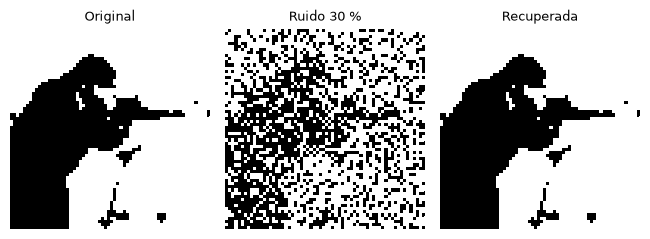

overlap inicial = 0.40,  final = 1.00
píxeles distintos al original: 0
E nunca aumenta: True;  E final = -2047.5 (directa: -2047.5)


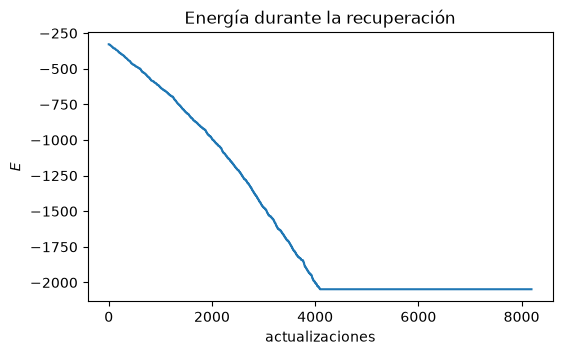

In [3]:
xi = imagen_a_estado(data.camera())
W = pesos_hebb(xi[None, :])

s_ruido = agregar_ruido(xi, 0.30, rng)
s_rec, E = recuperar(W, s_ruido, rng)

mostrar([xi, s_ruido, s_rec], ["Original", "Ruido 30 %", "Recuperada"])
print(f"overlap inicial = {overlap(s_ruido, xi):.2f},  final = {overlap(s_rec, xi):.2f}")
print(f"píxeles distintos al original: {np.sum(s_rec != xi)}")
print(f"E nunca aumenta: {np.all(np.diff(E) <= 1e-9)};  E final = {E[-1]:.1f} (directa: {energia(W, s_rec):.1f})")

plt.figure(figsize=(6, 3.5))
plt.plot(E)
plt.xlabel("actualizaciones")
plt.ylabel("$E$")
plt.title("Energía durante la recuperación")
plt.show()

1. Sí. Como $W$ es simétrica y $w_{ii}=0$, al cambiar $s_i$ la energía varía en $\Delta E=-\Delta s_i\,h_i\le 0$. La energía nunca aumenta y la dinámica se detiene en un mínimo local.
2. Con un solo patrón almacenado sí, el estado final coincide píxel a píxel con el original.

## 3. Nivel de ruido

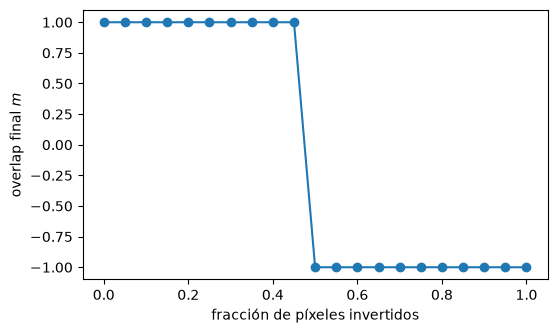

In [4]:
fracs = np.linspace(0, 1, 21)
m_final = [overlap(recuperar(W, agregar_ruido(xi, f, rng), rng)[0], xi) for f in fracs]

plt.figure(figsize=(6, 3.5))
plt.plot(fracs, m_final, "o-")
plt.xlabel("fracción de píxeles invertidos")
plt.ylabel("overlap final $m$")
plt.show()

3. Mientras menos de la mitad de los píxeles esté invertida, la imagen se recupera exactamente. Por encima del 50 % la red converge a $-\xi$, que es la imagen en negativo y también es un mínimo porque $E(s)=E(-s)$. Justo en el 50 % el resultado depende del orden de actualización (sección 5).

## 4. Varias imágenes

Se almacenan 8 imágenes de `skimage.data` y cada una se recupera a partir de una versión con 20 % de ruido. La tabla de abajo tiene los overlaps $\xi^\mu\cdot\xi^\nu/N$ entre ellas.

In [5]:
nombres = ["camera", "astronaut", "horse", "coffee", "moon", "coins", "chelsea", "page"]
patrones = np.array([imagen_a_estado(getattr(data, k)()) for k in nombres])
W = pesos_hebb(patrones)

pd.DataFrame(patrones @ patrones.T / patrones.shape[1], index=nombres, columns=nombres).round(2)

,camera,astronaut,horse,coffee,moon,coins,chelsea,page
camera,1.00,0.02,0.40,-0.02,0.17,0.10,0.05,0.43
astronaut,0.02,1.00,-0.06,0.18,0.17,0.01,-0.03,-0.01
horse,0.40,-0.06,1.00,-0.04,0.17,0.06,0.04,0.10
coffee,-0.02,0.18,-0.04,1.00,0.33,0.02,-0.07,0.18
moon,0.17,0.17,0.17,0.33,1.00,0.07,-0.07,0.08
coins,0.10,0.01,0.06,0.02,0.07,1.00,-0.03,0.01
chelsea,0.05,-0.03,0.04,-0.07,-0.07,-0.03,1.00,-0.01
page,0.43,-0.01,0.10,0.18,0.08,0.01,-0.01,1.00


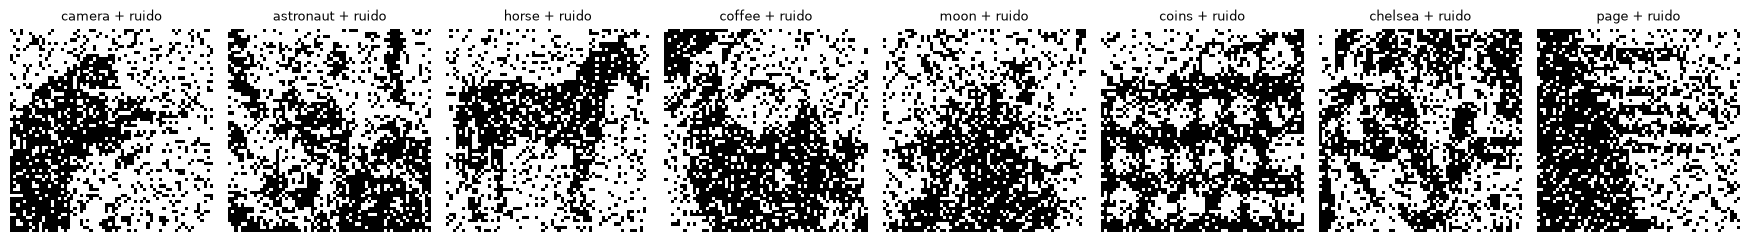

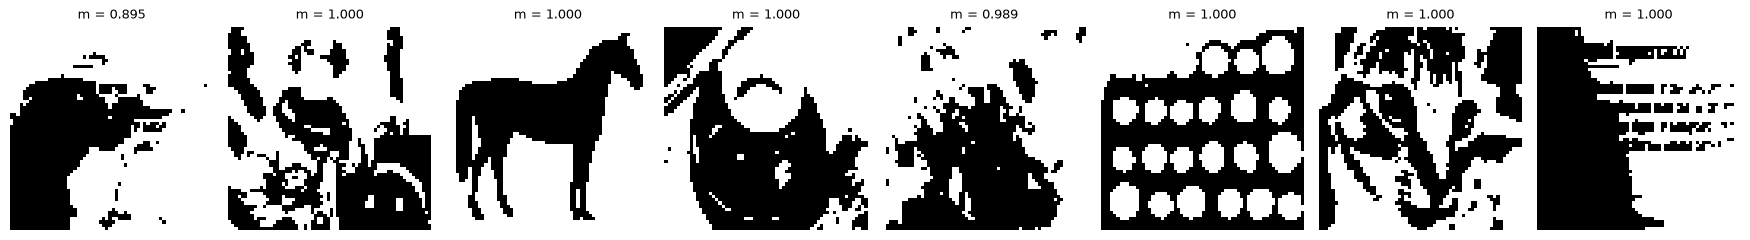

In [6]:
ruidosas = [agregar_ruido(p, 0.20, rng) for p in patrones]
recuperadas = [recuperar(W, s, rng)[0] for s in ruidosas]

mostrar(ruidosas, [f"{k} + ruido" for k in nombres])
mostrar(recuperadas, [f"m = {overlap(s, p):.3f}" for s, p in zip(recuperadas, patrones)])

4. Ocho imágenes son muy pocas comparadas con $0.138N\approx565$, pero no son patrones aleatorios. `camera` tiene un overlap cercano a 0.4 con `horse` y con `page`, entonces el término cruzado $\sum_{\nu\neq\mu}\xi^\nu(\xi^\nu\cdot s)/N$ deja de ser despreciable y la imagen se recupera con errores ($m\approx0.9$). Las imágenes poco correlacionadas sí se recuperan exactamente. Con esto se ve que la capacidad efectiva depende también de la correlación entre los patrones y no solo de cuántos son.

-astronaut es estable: True
desde estado aleatorio: máx |m| = 0.75 (moon)
desde estado aleatorio: máx |m| = 0.89 (camera)
desde estado aleatorio: máx |m| = 0.51 (camera)


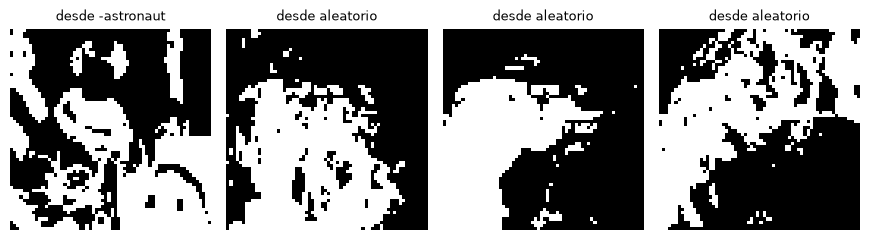

In [7]:
iniciales = [-patrones[1]] + [rng.choice([-1, 1], patrones.shape[1]) for _ in range(3)]
finales = [recuperar(W, s, rng)[0] for s in iniciales]

print("-astronaut es estable:", np.array_equal(finales[0], -patrones[1]))
for s in finales[1:]:
    m = overlap(s, patrones)
    print(f"desde estado aleatorio: máx |m| = {np.abs(m).max():.2f} ({nombres[np.abs(m).argmax()]})")
mostrar(finales, ["desde -astronaut"] + ["desde aleatorio"] * 3)

5. Sí aparecen. $-\xi^\mu$ siempre es un mínimo de la energía, y partiendo de estados aleatorios la red cae en puntos fijos que no coinciden con ninguna imagen almacenada ($|m|<1$ para todas). Son mezclas de varios patrones, que es justamente lo que caracteriza a un estado espurio. El estado final de `camera` en la sección 4 también es uno de ellos.

## 5. Orden de actualización

Se parte siempre del mismo estado ruidoso y solo cambia la semilla, es decir, el orden en que se visitan los píxeles.

In [8]:
semillas = range(8)

W1 = pesos_hebb(xi[None, :])
s0 = agregar_ruido(xi, 0.50, rng)
m = [overlap(recuperar(W1, s0, np.random.default_rng(k))[0], xi) for k in semillas]
print("1 patrón, 50 % de ruido -> overlap final:", np.round(m, 2))

s0 = agregar_ruido(patrones[0], 0.30, rng)
finales = [recuperar(W, s0, np.random.default_rng(k))[0] for k in semillas]
print("8 patrones, 30 % de ruido -> píxeles distintos al primer estado final:", [int(np.sum(f != finales[0])) for f in finales])

1 patrón, 50 % de ruido -> overlap final: [ 1.  1.  1. -1. -1.  1. -1. -1.]


8 patrones, 30 % de ruido -> píxeles distintos al primer estado final: [0, 0, 0, 0, 0, 0, 0, 0]


6. Depende del orden solo cerca de la frontera entre cuencas de atracción. Con un overlap inicial nulo (50 % de ruido), el orden es el que decide si se llega a $\xi$ o a $-\xi$. Lejos de esa frontera todas las secuencias terminan en el mismo estado.

## 6. Actualización sincrónica y asincrónica

En la actualización sincrónica todos los píxeles cambian a la vez, $s\leftarrow\operatorname{sign}(Ws)$. Para comparar las dos se usan 128 patrones aleatorios en una red de $N=512$ ($P/N=0.25$, por encima de la capacidad) y 10 estados iniciales con 30 % de ruido.

In [9]:
def sincronica(W, s, n_pasos=50):
    estados = [s]
    for _ in range(n_pasos):
        h = W @ s
        s = np.where(h == 0, s, np.sign(h))
        estados.append(s)
    return estados


aleatorios = rng.choice([-1, 1], size=(128, 512))
W_al = pesos_hebb(aleatorios)

ciclos, fijos = 0, 0
for _ in range(10):
    s0 = agregar_ruido(aleatorios[0], 0.30, rng)
    est = sincronica(W_al, s0)
    ciclos += np.array_equal(est[-1], est[-3]) and not np.array_equal(est[-1], est[-2])
    s_asin = recuperar(W_al, s0, rng)[0]
    fijos += np.array_equal(s_asin, sincronica(W_al, s_asin, 1)[-1])

print(f"sincrónica: {ciclos}/10 terminan en un ciclo de periodo 2")
print(f"asincrónica: {fijos}/10 terminan en un punto fijo")

sincrónica: 6/10 terminan en un ciclo de periodo 2
asincrónica: 10/10 terminan en un punto fijo


7. La asincrónica siempre termina en un punto fijo, porque ninguna actualización individual aumenta $E$. La sincrónica no tiene esa garantía, ya que al cambiar todos los píxeles con el campo del paso anterior puede quedarse oscilando entre dos estados.

## 7. Capacidad de memoria

Se almacenan $P$ patrones aleatorios en una red de $N=1024$ y la dinámica se inicia en cada patrón. Si el patrón es estable, el overlap final es 1.

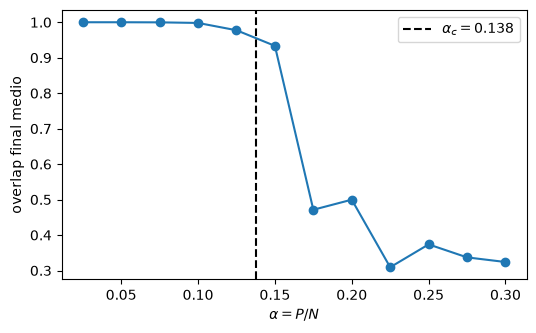

In [10]:
N = 1024
alfas = np.arange(0.025, 0.31, 0.025)
m_medio = []
for alfa in alfas:
    X = rng.choice([-1, 1], size=(int(alfa * N), N))
    W_c = pesos_hebb(X)
    m_medio.append(np.mean([overlap(recuperar(W_c, x, rng)[0], x) for x in X[:20]]))

plt.figure(figsize=(6, 3.5))
plt.plot(alfas, m_medio, "o-")
plt.axvline(0.138, color="k", ls="--", label=r"$\alpha_c = 0.138$")
plt.xlabel(r"$\alpha = P/N$")
plt.ylabel("overlap final medio")
plt.legend()
plt.show()

Hasta $P/N\approx0.12$ los patrones son prácticamente estables ($m\approx1$). Pasado $\alpha_c\approx0.138$ el overlap cae a valores entre 0.3 y 0.5 y la red deja de recuperar lo que tiene almacenado. Como $N$ es finito, la transición se suaviza y aparece un poco por encima de $\alpha_c$.